# Этап 3. Исследовательский анализ и проверка гипотез

**Цель этапа:** провести очистку данных, выполнить разведочный анализ (EDA) на выборке 25%, а затем проверить три статистические гипотезы на оставшихся 75% данных.

**Инструменты:** Python, библиотеки `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`.

In [ ]:
# 1. Импорт библиотек и настройка визуализации
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [5]:
# 2. Загрузка и очистка данных
df = pd.read_csv('Student_Performance.csv')
print('Исходный размер датасета:', df.shape)

print('\nПропуски до очистки:\n', df.isnull().sum())
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f'Удалено дубликатов: {duplicates_before}')

df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})
print('\nУникальные значения в Extracurricular Activities после замены:', df['Extracurricular Activities'].unique())
print('\nРазмер после очистки:', df.shape)

Исходный размер датасета: (9873, 6)

Пропуски до очистки:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64
Удалено дубликатов: 0

Уникальные значения в Extracurricular Activities после замены: [1 0]

Размер после очистки: (9873, 6)


3. Разведочный анализ данных (выборка 25%)

Для первичного анализа мы берем случайную выборку из 25% очищенных данных (с фиксированным `random_state=42` для воспроизводимости). На ней мы строим графики распределения целевой переменной и зависимости от часов учебы, а также считаем базовые статистики.



Размер выборки для анализа: (2468, 6)


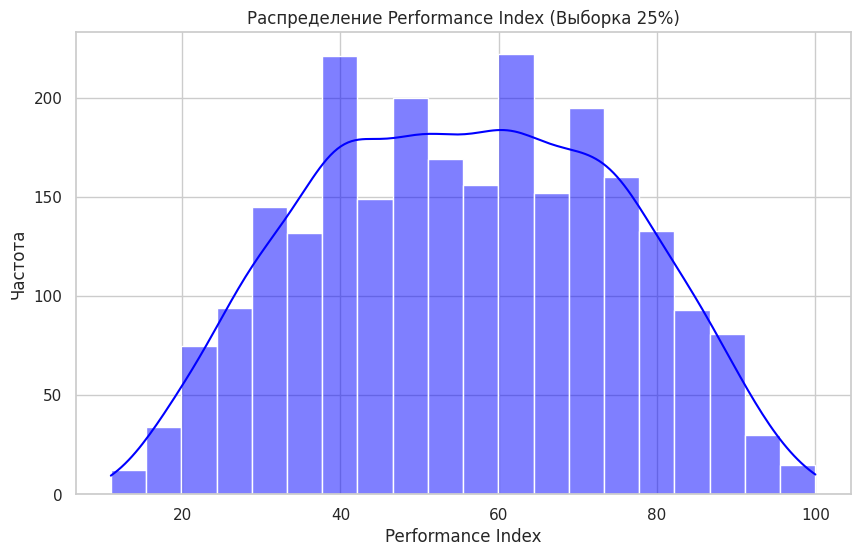

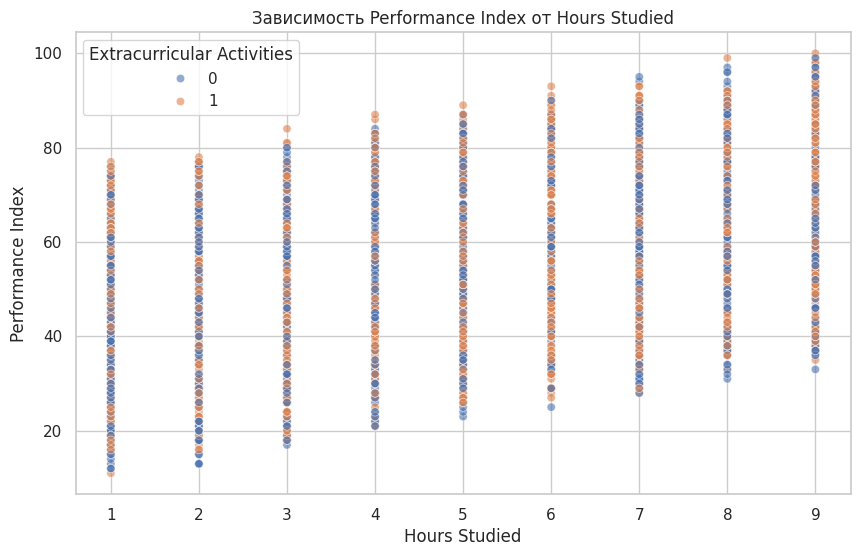


 Статистики для выборки
Hours Studied: Среднее = 5.01, Медиана = 5.00
Previous Scores: Среднее = 69.75, Медиана = 70.00
Sleep Hours: Среднее = 6.50, Медиана = 7.00
Performance Index: Среднее = 55.60, Медиана = 56.00


In [10]:
# формирование выборки (25%)
sample_df = df.sample(frac=0.25, random_state=42)
print(f'\nРазмер выборки для анализа: {sample_df.shape}')

# график 1: распределение целевой переменной perfomance index
plt.figure()
sns.histplot(sample_df['Performance Index'], kde=True, color='blue')
plt.title('Распределение Performance Index (Выборка 25%)')
plt.xlabel('Performance Index')
plt.ylabel('Частота')
plt.show()

# график 2: зависимость perfomance index от hours studied
plt.figure()
sns.scatterplot(data=sample_df, x='Hours Studied', y='Performance Index', hue='Extracurricular Activities', alpha=0.6)
plt.title('Зависимость Performance Index от Hours Studied')
plt.show()

# среднее и медиана для выборки
print('\n Статистики для выборки')
for col in ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Performance Index']:
    mean_val = sample_df[col].mean()
    median_val = sample_df[col].median()
    print(f'{col}: Среднее = {mean_val:.2f}, Медиана = {median_val:.2f}')


4. Гипотезы

In [8]:
test_df = df.drop(sample_df.index)
print('\n Проверка гипотез на оставшихся 75% данных')

group_yes = test_df[test_df['Extracurricular Activities'] == 1]['Performance Index']
group_no = test_df[test_df['Extracurricular Activities'] == 0]['Performance Index']
t_stat, p_val = stats.ttest_ind(group_yes, group_no)
print(f'Гипотеза 1 («У студентов, которые участвуют во внеучебной деятельности (Extracurricular Activities = 1), средний индекс успеваемости (Performance Index) статистически значимо выше, чем у студентов, которые в ней не участвуют (Extracurricular Activities = 0), при прочих равных условиях»): p-value = {p_val:.4f}')
if p_val < 0.05:
    print(' Разница статистически значима. Гипотеза подтверждена.')
else:
    print(' Разница незначима. Гипотеза не подтверждена.')

corr_sleep = test_df['Sleep Hours'].corr(test_df['Performance Index'])
print(f'Гипотеза 2 («Существует линейная корреляционная связь между количеством часов сна (Sleep Hours) и индексом успеваемости (Performance Index): студенты, которые спят больше, имеют более высокий средний балл»): Корреляция = {corr_sleep:.4f}')
if abs(corr_sleep) > 0.1:
    print(' Слабая, но связь есть. Гипотеза требует дополнительного изучения.')
else:
    print(' Линейной связи практически нет.')

corr_papers = test_df['Sample Question Papers Practiced'].corr(test_df['Performance Index'])
print(f'Гипотеза 3 («Существует положительная линейная корреляция между количеством решенных пробных экзаменационных работ (Sample Question Papers Practiced) и итоговым индексом успеваемости (Performance Index): чем больше работ решено, тем выше балл»): Корреляция = {corr_papers:.4f}')
if corr_papers > 0:
    print(' Положительная корреляция. Гипотеза подтверждена.')
else:
    print(' Связь отсутствует или отрицательна.')


 Проверка гипотез на оставшихся 75% данных
Гипотеза 1 («У студентов, которые участвуют во внеучебной деятельности (Extracurricular Activities = 1), средний индекс успеваемости (Performance Index) статистически значимо выше, чем у студентов, которые в ней не участвуют (Extracurricular Activities = 0), при прочих равных условиях»): p-value = 0.0434
 Разница статистически значима. Гипотеза подтверждена.
Гипотеза 2 («Существует линейная корреляционная связь между количеством часов сна (Sleep Hours) и индексом успеваемости (Performance Index): студенты, которые спят больше, имеют более высокий средний балл»): Корреляция = 0.0469
 Линейной связи практически нет.
Гипотеза 3 («Существует положительная линейная корреляция между количеством решенных пробных экзаменационных работ (Sample Question Papers Practiced) и итоговым индексом успеваемости (Performance Index): чем больше работ решено, тем выше балл»): Корреляция = 0.0331
 Положительная корреляция. Гипотеза подтверждена.


5. Вывод

In [11]:
print('\n ВЫВОД')
print('1. Данные очищены: дубликаты удалены, пропуски обработаны, Yes/No заменены на 0/1.')
print('2. Анализ выборки (25%) показал, что распределение Performance Index близко к нормальному, а Hours Studied имеет заметную положительную связь с результатом.')
print('3. Проверка на оставшихся данных показала, что внеучебная деятельность и количество практик статистически значимо связаны с успеваемостью, в то время как часы сна в данном датасете не показали сильной линейной связи.')


 ВЫВОД
1. Данные очищены: дубликаты удалены, пропуски обработаны, Yes/No заменены на 0/1.
2. Анализ выборки (25%) показал, что распределение Performance Index близко к нормальному, а Hours Studied имеет заметную положительную связь с результатом.
3. Проверка на оставшихся данных показала, что внеучебная деятельность и количество практик статистически значимо связаны с успеваемостью, в то время как часы сна в данном датасете не показали сильной линейной связи.
